# Librarary

In [4]:
import numpy as np
import seaborn as sns
import scipy 
from scipy import stats
import matplotlib.pyplot as plt

# Quiz

<ol>
    <li> n = 12 95% confidence level find critical values</li>
    <li> Sample size n of 10 appliances with a standard deviation of 0.15 volts . 
    <br>Construct a 95% confidence level for population variance and standard deviation </li>
</ol>

# Python Solution

In [11]:
# 1
n      = 12
dof    = n-1
cl     = 0.95
alpha  =1-cl
al_2   =alpha/2
chi_crr=stats.chi2.ppf(0.975,dof)  # chi is different than chi2 - chi2 is chi-square
chi_crl=stats.chi2.ppf(0.025,dof)  # reading of the chi2 table is reversed - as the table shows area to the right 
#  stats model's chi2 ppf refers to the area to the left that's why 0.025 is very small
print("chi_cirtical value left  : {:.2f} \nchi_critical value right :{:.2f}".format(chi_crl,chi_crr))

chi_cirtical value left  : 3.82 
chi_critical value right :21.92


In [57]:
# 2 
n     = 10 
dof   = n-1
s     = 0.15
s2    = s**2
cl    = 0.95 
alpahl=1-((1-cl)/2)
alphar=((1-cl)/2)
print("===chi square critical value===")
chi_cl= stats.chi2.ppf(alpahl,dof)
chi_cr= stats.chi2.ppf(alphar,dof)

print("chi_cirtical value left  : {:.4f}\nhi_critical value right  : {:.4f}".format(chi_cl,chi_cr))

print("")
print("========sample var 0.0225=======")
Lowerlimit_var= (s2*dof) /  chi_cr
upperlimit_var= (s2*dof) /  chi_cl

print("lowerlimit_var  : {:.4f}\nupperlimit_var  : {:.4f}".format(Lowerlimit_var,upperlimit_var))

print("========sample std 0.150========")
Lowerlimit_std= np.sqrt((s2*dof) /  chi_cr)
upperlimit_std= np.sqrt((s2*dof) /  chi_cl)

print("lowerlimit_std  : {:.4f}\nupperlimit_std  : {:.4f}".format(Lowerlimit_std,upperlimit_std))

===chi square critical value===
chi_cirtical value left  : 19.0228
hi_critical value right  : 2.7004

========sample var 0.0225=======
lowerlimit_var  : 0.0750
upperlimit_var  : 0.0106
========sample std 0.150========
lowerlimit_std  : 0.2738
upperlimit_std  : 0.1032


In [42]:
0.15**2

0.0225

# Simulation 

## Degrees of Freedom Simulation 

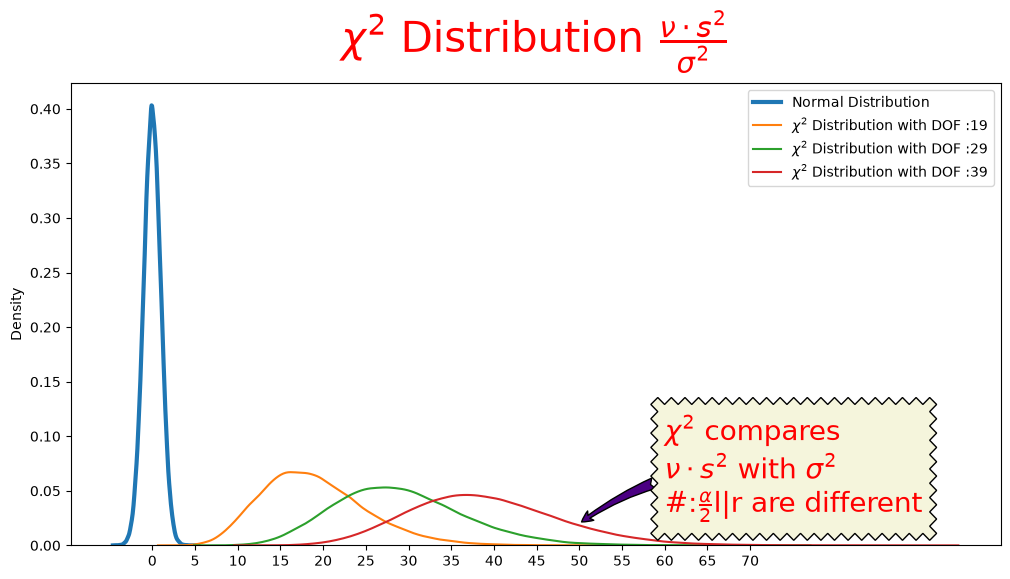

In [7]:
plt.figure(figsize=(12,6))
dof33     =[19,29,39]
size1     =100000

data_n    =np.random.randn(size1)
sns.kdeplot(data_n,lw=3,label="Normal Distribution")
for i in dof33:
    data_chi  = np.random.chisquare(df=i, size=size1 )
    sns.kdeplot(data_chi,label="$\\chi^2$ Distribution with DOF :{}".format(i))
    plt.legend()
plt.xticks(np.arange(0,75,5))
plt.title("$\\chi^2$ Distribution $\\frac{\\nu \\cdot s^2}{\\sigma^2}$",size=30,color="red",y=1.05)
plt.annotate("$\\chi^2$ compares \n$\\nu \\cdot s^2$ with $\\sigma^2$\n#:$\\frac{\\alpha}{2}$l|r are different",
             size=20,color="red",
             xytext=(60,0.03),
             bbox=dict(boxstyle="sawtooth,pad=0.5",facecolor="beige"),
             xy=(50,0.02),
             arrowprops=dict(arrowstyle="fancy",facecolor="indigo",connectionstyle="arc3,rad=0.2"))

plt.show()

## quiz1 

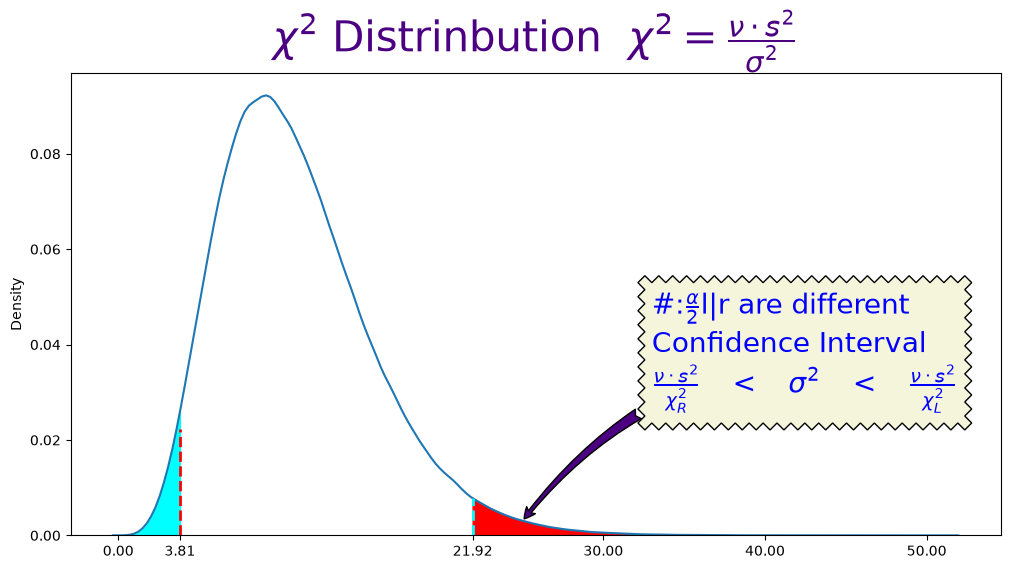

In [3]:
np.random.seed(0)
crti_l= 3.81
crti_r= 21.92
fi_siz= 100
data_chi = np.random.chisquare(df=11,size=1000000)

plt.figure(figsize=(12,6))
sns.kdeplot(data_chi)

x_fill1=np.linspace(0,crti_l,fi_siz)
y_fill1=stats.chi2.pdf(x_fill1,11)
plt.fill_between(x_fill1, y_fill1, color="cyan")

x_fill2=np.linspace(crti_r,40,fi_siz)
y_fill2=stats.chi2.pdf(x_fill2,11)
plt.fill_between(x_fill2, y_fill2, color="red")

plt.annotate("#:$\\frac{\\alpha}{2}$l|r are different\nConfidence Interval \n$\\frac{\\nu \\cdot s^2}{\\chi^2_R} \\quad< \\quad\\sigma^2 \\quad<\\quad \\frac{\\nu \\cdot  s^2}{\\chi^2_{L}}$",
             size=20,color="blue",
             xytext=(33,0.03),
             bbox=dict(boxstyle="sawtooth,pad=0.5",facecolor="beige"),
             xy=(25,0.003),
             arrowprops=dict(arrowstyle="fancy",facecolor="indigo",connectionstyle="arc3,rad=0.2"))
plt.xticks([0,crti_l,crti_r,30,40,50])
plt.title("$\\chi^2$ Distrinbution  $\\chi^2=\\frac{\\nu \\cdot s^2}{\\sigma^2}$",color="indigo",size=30)

plt.axvline(crti_l,0,0.23,lw=2,ls="--",color="red")
plt.axvline(crti_r,0,0.08,lw=2,ls="--",color="cyan")
plt.show()